# Transformasi Data Prediksi Hasil Tes LPDP
**Studi Kasus:** memprediksi kelulusan Seleksi Substansi Akademik LPDP Gelombang I 2021 dari data hasil tes SBK. 

**Alur pengerjaan** 
1. Eksplorasi setiap kolom fitur dan pemilihan trnsformasi yang sesuai.
2. Transformasi data campuran dengan 'ColumnTransformer' (≥ 3 jenis transformasi), lalu simpan ke file baru lewat proses **ETL**.
3. Prediksi kelulusan **hanya dari file hasil ETL** (tanpa membuka raw data).
4. Bandingkan akurasi tanpa transformasi vs. dengan transformasi. 

In [2]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler, RobustScaler, PowerTransformer, KBinsDiscretizer)
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
OUT_DIR = 'output_etl'
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Eksplorasi Data

### 1.1 Extract - membaca data mentah 

In [3]:
RAW_PATH = 'lpdp.csv'
df_raw = pd.read_csv(RAW_PATH)
print(df_raw.shape)
df_raw.head()

(472, 11)


,Timestamp,Jenis Beasiswa,Tingkat Pendidikan yang Dituju,Negara Tujuan Kuliah,Bidang Studi yang dipilih saat mendaftar,Mendaftar dengan menggunakan LoA sesuai ketentuan LPDP,Apakah anda dinyatakan Lulus Seleksi Substansi Akademik Pada gelombang I Tahun 2021?,Jumlah Jawaban Benar pada Tes Penalaran Verbal,Jumlah Jawaban Benar pada Tes Kuantitatif,Jumlah Jawaban Benar pada Tes Pemecahan Masalah,[optional] Kampus/universitas tujuan saat ini (pilihan 1)
0,6/24/2021 15:54:15,Targeted,S2,Dalam negeri,TRP,Tidak,Ya,10,12,6,Universitas Indonesia
1,6/24/2021 15:54:22,Reguler,S2,Luar Negeri,ENE,"Ya, dengan Loa",Ya,17,22,8,UCL
2,6/24/2021 15:54:54,Targeted,S2,Luar Negeri,ELE,"Ya, dengan Loa",Ya,16,18,7,KTH Sweden
3,6/24/2021 15:56:06,Reguler,S2,Dalam negeri,LIN,Tidak,Tidak,15,12,4,UGM
4,6/24/2021 15:56:28,Afirmasi,S2,Luar Negeri,LIN,Tidak,Ya,16,9,7,University of Birmingham


In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 472 entries, 0 to 471
Data columns (total 11 columns):
 #   Column                                                                                Non-Null Count  Dtype 
---  ------                                                                                --------------  ----- 
 0   Timestamp                                                                             472 non-null    object
 1   Jenis Beasiswa                                                                        472 non-null    object
 2   Tingkat Pendidikan yang Dituju                                                        472 non-null    object
 3   Negara Tujuan Kuliah                                                                  472 non-null    object
 4   Bidang Studi yang dipilih saat mendaftar                                              472 non-null    object
 5   Mendaftar dengan menggunakan LoA sesuai ketentuan LPDP                                472 no

In [5]:
NAMA_BARU = ['timestamp', 'jenis', 'tingkat', 'negara', 'bidang', 'loa', 'lulus', 'verbal', 'kuantitatif', 'masalah', 'kampus']
df = df_raw.copy()
df.columns = NAMA_BARU
df['lulus_bin'] = (df['lulus'] == 'Ya').astype(int)
df.head()

,timestamp,jenis,tingkat,negara,bidang,loa,lulus,verbal,kuantitatif,masalah,kampus,lulus_bin
0,6/24/2021 15:54:15,Targeted,S2,Dalam negeri,TRP,Tidak,Ya,10,12,6,Universitas Indonesia,1
1,6/24/2021 15:54:22,Reguler,S2,Luar Negeri,ENE,"Ya, dengan Loa",Ya,17,22,8,UCL,1
2,6/24/2021 15:54:54,Targeted,S2,Luar Negeri,ELE,"Ya, dengan Loa",Ya,16,18,7,KTH Sweden,1
3,6/24/2021 15:56:06,Reguler,S2,Dalam negeri,LIN,Tidak,Tidak,15,12,4,UGM,0
4,6/24/2021 15:56:28,Afirmasi,S2,Luar Negeri,LIN,Tidak,Ya,16,9,7,University of Birmingham,1


### 1.2 Target: `lulus`

lulus
Ya       347
Tidak    125
Name: count, dtype: int64

lulus
Ya       0.7352
Tidak    0.2648
Name: proportion, dtype: float64

Akurasi jika selalu menebak 'Ya' (majority baseline): 0.7352


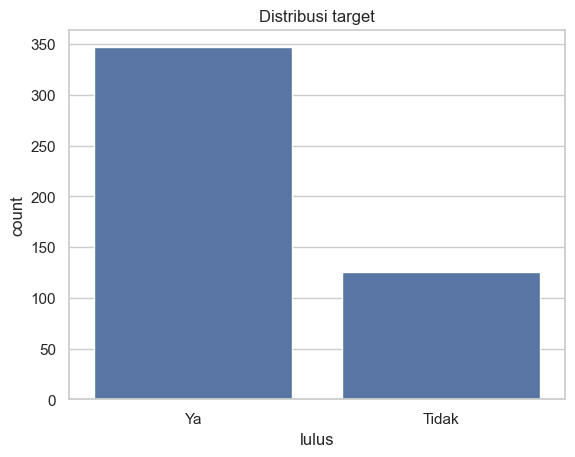

In [6]:
print(df['lulus'].value_counts())
print()
print(df['lulus'].value_counts(normalize=True).round(4))
MAJORITY = df['lulus_bin'].mean()
print(f"\nAkurasi jika selalu menebak 'Ya' (majority baseline): {MAJORITY:.4f}")
sns.countplot(data=df, x="lulus", order=['Ya', 'Tidak'])
plt.title('Distribusi target')
plt.show()

Kelas **tidak seimbang** (±73,5% lulus). Artinya model yang selalu menebak "Ya" sudah mendapat akurasi ±0,735. 

### 1.3 Fitur Kategorikal

In [10]:
for c in df.select_dtypes(exclude='number').drop(columns=['timestamp', 'lulus']):
    print(f"=== {c} ({df[c].nunique()} unik) ===")
    print(df[c].value_counts(dropna=False).head(10), '\n')

=== jenis (3 unik) ===
jenis
Reguler     261
Targeted    118
Afirmasi     93
Name: count, dtype: int64 

=== tingkat (2 unik) ===
tingkat
S2    415
S3     57
Name: count, dtype: int64 

=== negara (2 unik) ===
negara
Luar Negeri     258
Dalam negeri    214
Name: count, dtype: int64 

=== bidang (90 unik) ===
bidang
TRP    110
BUS     47
PUB     23
SOS     15
FOR     15
IPA     14
DEV     12
ICT     12
EDU     11
ARC     11
Name: count, dtype: int64 

=== loa (2 unik) ===
loa
Tidak             335
Ya, dengan Loa    137
Name: count, dtype: int64 

=== kampus (183 unik) ===
kampus
NaN                        92
UGM                        40
ITB                        25
UI                         21
UCL                        16
Universitas Indonesia      12
Universitas Gadjah Mada    11
UNY                         5
University of Melbourne     5
Columbia University         5
Name: count, dtype: int64 



=== jenis ===
lulus     Tidak   Ya  %lulus
jenis                       
Afirmasi     13   80    86.0
Reguler      93  168    64.4
Targeted     19   99    83.9 

=== tingkat ===
lulus    Tidak   Ya  %lulus
tingkat                    
S2         107  308    74.2
S3          18   39    68.4 

=== negara ===
lulus         Tidak   Ya  %lulus
negara                          
Dalam negeri     68  146    68.2
Luar Negeri      57  201    77.9 

=== loa ===
lulus           Tidak   Ya  %lulus
loa                               
Tidak              94  241    71.9
Ya, dengan Loa     31  106    77.4 



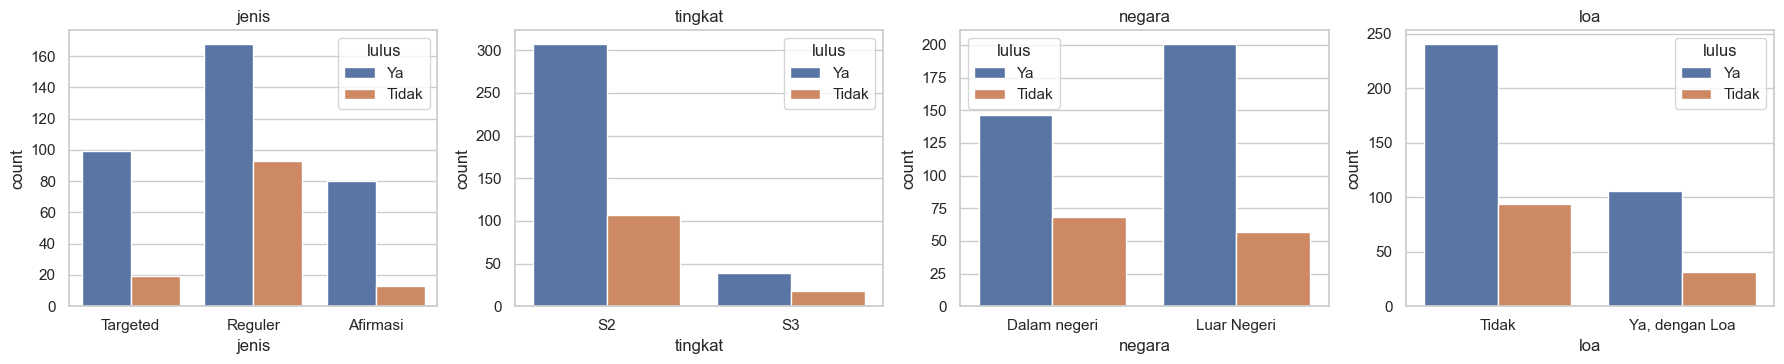

In [8]:
kolom_kat_kecil = ['jenis', 'tingkat', 'negara', 'loa']
for c in kolom_kat_kecil:
    print(f"=== {c} ===")
    tab = pd.crosstab(df[c], df['lulus'], margins=False)
    tab['%lulus'] = (tab['Ya'] / tab.sum(axis=1) * 100).round(1)
    print(tab, '\n')

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, c in zip(ax, kolom_kat_kecil): 
    sns.countplot(data=df, x=c, hue='lulus', hue_order=['Ya', 'Tidak'], ax=a)
    a.set_title(c)
plt.tight_layout()
plt.show()

In [11]:
print('Jumlah nilai unik bidang (mentah):', df['bidang'].nunique())
print(sorted(df['bidang'].unique()))

Jumlah nilai unik bidang (mentah): 90
['-', '000', '718', 'ACC', 'ACF', 'AER', 'AFR', 'AGB', 'ANT', 'ARC', 'ART', 'ATM', 'Afr', 'BIO', 'BK', 'BUS', 'Bio', 'BuS', 'Bus', 'CBS', 'CE', 'CHE', 'CIV', 'COM', 'Civ', 'DEF', 'DEV', 'Dev', 'EAM', 'ECO', 'ECT', 'EDU', 'EDu', 'ELE', 'ENE', 'ENG', 'ENT', 'ENV', 'ETC', 'Edu', 'FIN', 'FOO', 'FOR', 'For', 'GEO', 'HOS', 'HUM', 'Hum', 'ICT', 'INS', 'IPA', 'Ipa', 'KES', 'LAW', 'LIN', 'LNY', 'Law', 'M', 'MAR', 'MAT', 'MED', 'MET', 'MIN', 'NUR', 'OCE', 'OTH', 'PHA', 'PHY', 'POL', 'PSY', 'PTK', 'PUB', 'Pen', 'Psi', 'SGY', 'SOC', 'SOS', 'SOs', 'STA', 'TEK', 'TEL', 'TFM', 'TP', 'TRA', 'TRP', 'Tra', 'Trp', 'WAT', 'arc', 'bus']


`bidang` berisi **90 nilai unik** dan sebagian hanya beda huruf besar/kecil (`Dev` vs `DEV`, `BUS` vs `BUS` vs `Bus`). Ada juga nilai yang tidak ada artinya seperti `-`, `000`, `718`, `M`). Ada juga singkatan berbahasa Indonesia yang sudah ada padanannya seperti `Pen` dan `EDU`, `Psi` dengan `PSY`. Teks harus dibersihkan terlebih dahulu, lalu One-Hot dengan `min_frequency`. 

In [12]:
def bersihkan_bidang(s):
    s = s.astype(str).str.strip().str.upper()
    s = s.replace({'PEN': 'EDU', 'PSI': 'PSY'})
    s = s.where(s.str.fullmatch(r'[A-Z]{2,}'), 'LAINNYA')
    return s

bidang_bersih = bersihkan_bidang(df['bidang'])
print('Unik sebelum:', df['bidang'].nunique(), '| sesudah:' , bidang_bersih.nunique())
vc = bidang_bersih.value_counts()
print('Kategori dengan >= 10 data:', (vc >= 10).sum(), '| kategori dengan < 10 data:', (vc < 10).sum())
vc.head(12)

Unik sebelum: 90 | sesudah: 68
Kategori dengan >= 10 data: 10 | kategori dengan < 10 data: 58


bidang
TRP    111
BUS     55
PUB     23
FOR     16
SOS     16
IPA     15
EDU     14
DEV     14
ARC     12
ICT     12
LAW      9
COM      9
Name: count, dtype: int64

In [13]:
print('Tidak ada kampus:', df['kampus'].isna().sum(), f"({df['kampus'].isna().mean():.1%})")
print('Kampus unik (mentah):', df['kampus'].nunique())
df['kampus'].value_counts().head(15)

Tidak ada kampus: 92 (19.5%)
Kampus unik (mentah): 183


kampus
UGM                         40
ITB                         25
UI                          21
UCL                         16
Universitas Indonesia       12
Universitas Gadjah Mada     11
UNY                          5
University of Melbourne      5
Columbia University          5
Universitas Airlangga        5
University of Manchester     5
TU Delft                     4
University of Edinburgh      4
ANU                          4
IPB                          4
Name: count, dtype: int64

`kampus` adalah isian **opsional**: 92 barus (±19,5%) kosong, dan penulisannya tidak seragam (`UGM`, `Ugm`, `Universitas Gadjah Mada`; `UI`, `Universitas Indonesia`; dst.). 
- Perlu penyeragaman penulisan kampus yang sering muncul. 
- Nilai kosong diisi `TIDAK_DIISI` dan dibuat fitur biner `kampus_terisi`
- One-Hot dengan `mean_frequency` sepserti `bidang`.

In [14]:
ALIAS_KAMPUS = {
    'ugm': 'UGM', 'universitas gadjah mada': 'UGM',
    'ui': 'UI', 'universitas indonesia': 'UI',
    'itb': 'ITB', 'institut teknologi bandung': 'ITB', 
    'ipb': 'IPB', 'institut pertanian bogor': 'IPB', 
    'upi': 'UPI', 'universitas pendidikan indonesia': 'UPI', 
    'unair': 'UNAIR', 'universitas airlangga': 'UNAIR', 
    'its': 'ITS', 'institut teknologi sepuluh november': 'ITS', 
    'unesa': 'UNESA', 'universitas negeri surabaya': 'UNESA', 
    'um': 'UM', 'universitas negeri malang': 'UM',
    'uny': 'UNY', 'universitas negeri yogyakarta': 'UNY',
    'wur': 'WUR', 'wageningen university and research': 'WUR', 'wageningen university': 'WUR',
    'ucl': 'UCL', 'university college london': 'UCL', 
    'icl': 'ICL', 'imperial college london': 'ICL',
    'kcl': 'KCL', "king's college london": 'KCL', 
    'lse': 'LSE', 'london school of economics': 'LSE', 'london school of economics and political science': 'LSE', 
    'nus': 'NUS', 'national university of singapore': 'NUS', 
    'anu': 'ANU', 'australian national university': 'ANU', 
    'tu delft': 'TU DELFT', 'tudelft': 'TUDELFT', 'delft university of technology': 'TU DELFT', 
}

def bersihkan_kampus(s):
    s = s.fillna('').str.strip().str.lower()
    return s.map(lambda x: ALIAS_KAMPUS.get(x, x.title() if x else 'TIDAK_DIISI'))

kampus_bersih = bersihkan_kampus(df['kampus'])
print('Unik sebelum:', df['kampus'].nunique(), '|sesudah:', kampus_bersih.nunique())
kampus_bersih.value_counts().head(10)

Unik sebelum: 183 |sesudah: 145


kampus
TIDAK_DIISI    92
UGM            57
UI             38
ITB            27
UCL            17
WUR             9
UPI             7
IPB             7
UNAIR           7
UNY             6
Name: count, dtype: int64

### 1.4 Fitur numerik (skor tes)

,count,mean,std,min,25%,50%,75%,max
verbal,472.0,15.13,2.72,0.0,13.0,15.0,17.0,23.0
kuantitatif,472.0,14.47,4.36,0.0,12.0,15.0,18.0,25.0
masalah,472.0,6.18,1.83,0.0,5.0,6.0,7.0,12.0



Skewness:
 verbal        -0.587
kuantitatif   -0.138
masalah        0.156
dtype: float64

Rata-rata skor per kelompok target:


,verbal,kuantitatif,masalah
lulus,,,
Tidak,14.71,11.20,5.87
Ya,15.29,15.65,6.29


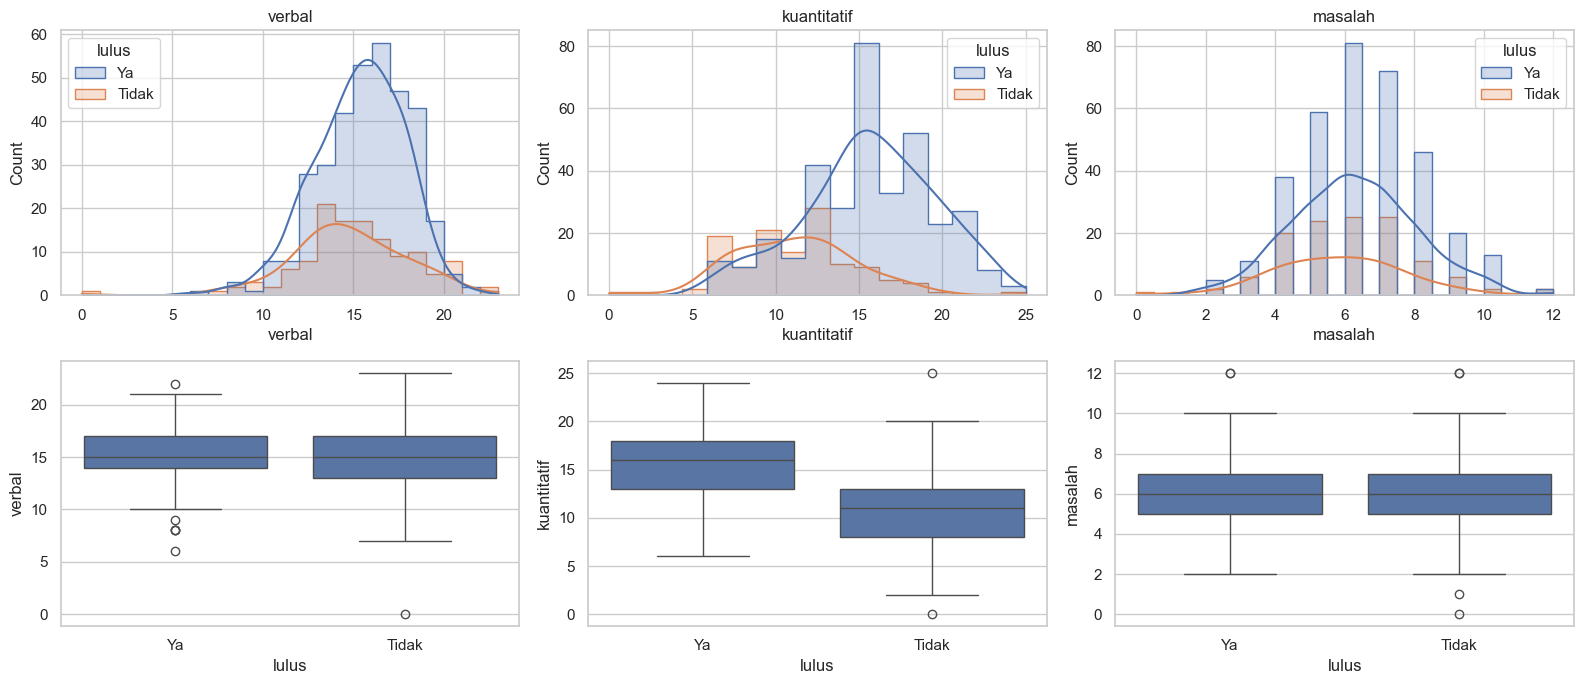

In [18]:
num_cols = ['verbal', 'kuantitatif', 'masalah']
display(df[num_cols].describe().T.round(2))
print('\nSkewness:\n', df[num_cols].skew().round(3))
print('\nRata-rata skor per kelompok target:')
display(df.groupby('lulus')[num_cols].mean().round(2))

fig, ax = plt.subplots(2, 3, figsize=(16, 7))
for j, c in enumerate(num_cols):
    sns.histplot(data=df, x=c, hue='lulus', kde=True, ax=ax[0, j], element='step')
    sns.boxplot(data=df, x='lulus', y=c, order=['Ya', 'Tidak'], ax=ax[1, j])
    ax[0, j].set_title(c)
plt.tight_layout()
plt.show()

- Ketiga skor berupah **integer** dengan skala berbeda: `verbal` 0-23, `kuantitatif` 0-25, `masalah` 0-12 -> perlu ada **penskalaan** agar model berbasis jarak (KNN, SVM) dan model linear tidak didominasi fitur berskala besar. 
- Ada beberapa **outlier** -> `RobustScaler` layak dibandingkan dengan `StandardScaler` dan `MinMaxSacler`.
- `kuantitatif` adalah pembeda terkuat antara yang lulus dan tidak (selisih rata-rata terbesar); `verbal` dan `masalah` selisihnya kecil. 
- Distribusi sedikit miring -> `PowerTransformer` (Yeo-Johnson) dicoba sebagai transformasi lebih lanjut.

### 1.5 Kolom `timestamp`

In [20]:
ts = pd.to_datetime(df['timestamp'], format='%m/%d/%Y %H:%M:%S')
print(ts.min(), '->', ts.max())
print('Jumlah hari berbeda:', ts.dt.date.nunique())
print(df.assign(tgl=ts.dt.date).groupby('tgl')['lulus_bin'].agg(['count', 'mean']).round(2).head(8))

2021-06-24 15:54:15 -> 2023-03-29 11:56:48
Jumlah hari berbeda: 35
            count  mean
tgl                    
2021-06-24    296  0.86
2021-06-25     41  0.83
2021-06-26      9  0.56
2021-06-27      3  0.67
2021-06-28      7  0.86
2021-06-30      5  1.00
2021-07-01      9  0.56
2021-07-02      4  0.75


`timestmap` hanya waktu pengisian formulir, tidak relevan sebagai fitur. Kolom ini bisa di-drop.

### 1.6 Ringkasan keputusan transformasi per kolom

| Kolom | Jenis data | Transformasi yang dipilih | Alasan |
|---|---|---|---|
| `timestamp` | waktu | **Drop** | tidak mencerminkan karakteristik pelamar |
| `jenis` | nominal (3) | **OneHotEncoder** | tidak ada urutan antar kategori |
| `tingkat` | ordinal (S2 < S3) | **OrdinalEncoder** (urutan eksplisit) | ada urutan jenjang |
| `negara` | biner | **OneHotEncoder(drop='if_binary')** | cukup 1 kolom 0/1 |
| `loa` | biner | **OneHotEncoder(drop='if_binary')** | cukup 1 kolom 0/1 |
| `bidang` | nominal, kardinalitas tinggi | pembersihan teks + **OneHotEncoder(min_frequency)** | kategori jarang digabung, hindari puluhan kolom hampir kosong |
| `kampus` | nominal, kardinalitas tinggi, 19,5% kosong | pembersihan + isi `TIDAK_DIISI` + **OneHotEncoder(min_frequency)** | sama dengan `bidang` |
| `kampus_terisi` *(fitur baru)* | biner | **passthrough** | menandai isian opsional dikosongkan atau tidak |
| `verbal`, `kuantitatif`, `masalah` | numerik cacah | **Scaler** (Robust / MinMax / Standard) atau **PowerTransformer** | skala berbeda, ada outlier & kemiringan |
| `skor_total` *(fitur baru)* | numerik | **KBinsDiscretizer** (5 bin kuantil, one-hot) | menangkap efek non-linear skor total |
| `lulus` | target | Ya → 1, Tidak → 0 | label biner |

## 2. Transform & Load -- `ColumnTransformer` + ETL

Proses ETL dibungkus dalam tiga fungsi: `extract()` -> `transform()` -> `load()`

**8 varian dataset hasil transformasi**: 

| Varian | Kategorikal | Numerik |
|---|---|---|
| `OHE_ROBUST`, `OHE_MINMAX`, `OHE_STANDARD` | One-hot (+ ordinal untuk `tingkat`) | Robust / MinMax / Standard Scaler |
| `ORD_ROBUST`, `ORD_MINMAX`, `ORD_STANDARD` | Ordinal Encover untuk semua kolom kategorikal | Robust / MinMax / Standard Scaler |
| `Custom` | One-Hot + ordinal (tanpa urutan palsu) | **PowerTrasnformer** untuk 3 skor + **KBinsDiscretizer** untuk `skor_total` |

Seluruh varian memakai `ColumnTransformer`, sehingga kolom kategorikal, biner, ordinal, dan numerik diperlakukan berbeda-beda (transformasi campuran). 

In [26]:
def extract(path=RAW_PATH):
    d = pd.read_csv(path)
    d.columns = NAMA_BARU
    return d

def bersihkan_dan_rekayasa_fitur(d):
    d = d.copy()
    d['bidang'] = bersihkan_bidang(d['bidang'])
    d['kampus_terisi'] = d['kampus'].notna().astype(int)
    d['kampus'] = bersihkan_kampus(d['kampus'])
    d['skor_total'] = d['verbal'] + d['kuantitatif'] + d['masalah']
    d['lulus_bin'] = (d['lulus'] == 'Ya').astype(int)
    return d

KOL_NOMINAL_KECIL = ['jenis']
KOL_ORDINAL = ['tingkat']
KOL_BINER = ['negara', 'loa']
KOL_NOMINAL_BESAR = ['bidang', 'kampus'] 
KOL_SKOR = ['verbal', 'kuantitatif', 'masalah']
KOL_KATEGORIKAL = KOL_NOMINAL_KECIL + KOL_ORDINAL + KOL_BINER + KOL_NOMINAL_BESAR

def buat_column_transformer(varian):
    enc, _, scl = varian.partition('_')
    scalers = {'ROBUST': RobustScaler, 'MINMAX': MinMaxScaler, 'STANDARD': StandardScaler}

    if varian == 'CUSTOM': 
        transformers = [
            ('jenis_ohe', OneHotEncoder(sparse_output=False), KOL_NOMINAL_KECIL),
            ('tingkat_ord', OrdinalEncoder(categories=[['S2', 'S3']]), KOL_ORDINAL),
            ('biner_ohe', OneHotEncoder(drop='if_binary', sparse_output=False), KOL_BINER),
            ('besar_ohe', OneHotEncoder(min_frequency=10, handle_unknown='infrequent_if_exist', sparse_output=False), KOL_NOMINAL_BESAR),
            ('skor_power', PowerTransformer(method='yeo-johnson'), KOL_SKOR),
            ('total_bin', KBinsDiscretizer(n_bins=5, encode='onehot-dense', strategy='quantile'), ['skor_total']), 
            ('kampus_flag', 'passthrough', ['kampus_terisi']),
        ]

    elif enc =='OHE':
        transformers = [
            ('jenis_ohe', OneHotEncoder(sparse_output=False), KOL_NOMINAL_KECIL), 
            ('tingkat_ord', OrdinalEncoder(categories=[['S2', 'S3']]), KOL_ORDINAL),
            ('biner_ohe', OneHotEncoder(drop='if_binary', sparse_output=False), KOL_BINER),
            ('besar_ohe', OneHotEncoder(min_frequency=10, handle_unknown='infrequent_if_exist', sparse_output=False), KOL_NOMINAL_BESAR),
            ('skor_scale', scalers[scl](), KOL_SKOR + ['skor_total']),
            ('kampus_flag', 'passthrough', ['kampus_terisi']),
        ]

    else: 
        transformers = [
            ('kat_ord', OrdinalEncoder(), KOL_KATEGORIKAL), 
            ('skor_scale', scalers[scl](), KOL_SKOR + ['skor_total']),
            ('kampus_flag', 'passthrough', ['kampus_terisi']),
        ]

    ct = ColumnTransformer(transformers, remainder='drop')
    ct.set_output(transform='pandas')
    return ct

def transform(d, varian):
    d = bersihkan_dan_rekayasa_fitur(d)
    ct = buat_column_transformer(varian)
    X = ct.fit_transform(d)
    X.columns = [c.split('__', 1)[1] for c in X.columns]
    X['lulus'] = d['lulus_bin'].values
    return X, ct

def load(X, varian, out_dir=OUT_DIR):
    path = os.path.join(out_dir, f'lpdp_etl_{varian}.csv')
    X.to_csv(path, index=False)
    return path

VARIAN = ['OHE_ROBUST', 'OHE_MINMAX', 'OHE_STANDARD', 'ORD_ROBUST', 'ORD_MINMAX', 'ORD_STANDARD', 'CUSTOM']

In [27]:
raw = extract()
hasil_etl = {}
for v in VARIAN:
    X_v, ct_v = transform(raw, v)
    path = load(X_v, v)
    hasil_etl[v] = path
    print(f'{v:13s} -> {path:38s} bentuk = {X_v.shape}')

OHE_ROBUST    -> output_etl/lpdp_etl_OHE_ROBUST.csv     bentuk = (472, 29)
OHE_MINMAX    -> output_etl/lpdp_etl_OHE_MINMAX.csv     bentuk = (472, 29)
OHE_STANDARD  -> output_etl/lpdp_etl_OHE_STANDARD.csv   bentuk = (472, 29)
ORD_ROBUST    -> output_etl/lpdp_etl_ORD_ROBUST.csv     bentuk = (472, 12)
ORD_MINMAX    -> output_etl/lpdp_etl_ORD_MINMAX.csv     bentuk = (472, 12)
ORD_STANDARD  -> output_etl/lpdp_etl_ORD_STANDARD.csv   bentuk = (472, 12)
CUSTOM        -> output_etl/lpdp_etl_CUSTOM.csv         bentuk = (472, 33)


In [28]:
X_custom, ct_custom = transform(raw, 'CUSTOM')
print('Kolom hasil transformasi CUSTOM: ')
print(list(X_custom.columns))
X_custom.head()

Kolom hasil transformasi CUSTOM: 
['jenis_Afirmasi', 'jenis_Reguler', 'jenis_Targeted', 'tingkat', 'negara_Luar Negeri', 'loa_Ya, dengan Loa', 'bidang_ARC', 'bidang_BUS', 'bidang_DEV', 'bidang_EDU', 'bidang_FOR', 'bidang_ICT', 'bidang_IPA', 'bidang_PUB', 'bidang_SOS', 'bidang_TRP', 'bidang_infrequent_sklearn', 'kampus_ITB', 'kampus_TIDAK_DIISI', 'kampus_UCL', 'kampus_UGM', 'kampus_UI', 'kampus_infrequent_sklearn', 'verbal', 'kuantitatif', 'masalah', 'skor_total_0.0', 'skor_total_1.0', 'skor_total_2.0', 'skor_total_3.0', 'skor_total_4.0', 'kampus_terisi', 'lulus']


,jenis_Afirmasi,jenis_Reguler,jenis_Targeted,tingkat,negara_Luar Negeri,"loa_Ya, dengan Loa",bidang_ARC,bidang_BUS,bidang_DEV,bidang_EDU,...,verbal,kuantitatif,masalah,skor_total_0.0,skor_total_1.0,skor_total_2.0,skor_total_3.0,skor_total_4.0,kampus_terisi,lulus
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-1.785736,-0.580870,-0.081742,1.0,0.0,0.0,0.0,0.0,1,1
1,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.675490,1.761816,0.997823,0.0,0.0,0.0,0.0,1.0,1,1
2,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.272313,0.808468,0.462093,0.0,0.0,0.0,0.0,1.0,1,1
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.114197,-0.580870,-1.199466,0.0,1.0,0.0,0.0,0.0,1,0
4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.272313,-1.252141,0.462093,0.0,1.0,0.0,0.0,0.0,1,1


In [30]:
for v, p in hasil_etl.items():
    t = pd.read_csv(p)
    print(f'{v:13s} NaN={int(t.isna().sum().sum())} kolom konstan={int((t.nunique() <= 1).sum())}')

OHE_ROBUST    NaN=0 kolom konstan=0
OHE_MINMAX    NaN=0 kolom konstan=0
OHE_STANDARD  NaN=0 kolom konstan=0
ORD_ROBUST    NaN=0 kolom konstan=0
ORD_MINMAX    NaN=0 kolom konstan=0
ORD_STANDARD  NaN=0 kolom konstan=0
CUSTOM        NaN=0 kolom konstan=0


## 3. Prediksi Kelulusan (hanya dari file hasil ETL)

Evaluasi memakai dua cara agar hasil tidak bergantung pada satu pembagian data yang kebetulan:
- Hold-out: 80% train / 20% test (stratified, `random_state=42`)
- Cross-validation: 5-fold stratified x 3 pengulangan; dilaporkan rata-rata akurasi.

In [33]:
def buat_model():
    return {
        'Logistic Regression': LogisticRegression(max_iter=2000),
        'KNN': KNeighborsClassifier(),
        'SVM': SVC(),
        'Naive-Bayes': GaussianNB(),
        'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
        'Linear Discriminant Analysis': LinearDiscriminantAnalysis(),
        'Ada Boost': AdaBoostClassifier(random_state=RANDOM_STATE),
        'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    }

CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

def evaluasi(X, y):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    ho, cv = {}, {}
    for nama, m in buat_model().items():
        m.fit(Xtr, ytr)
        ho[nama] = accuracy_score(yte, m.predict(Xte))
        cv[nama] = cross_val_score(buat_model()[nama], X, y, cv=CV, scoring='accuracy').mean()
    return ho, cv

ho_hasil, cv_hasil = {}, {}
for v, p in hasil_etl.items():
    data = pd.read_csv(p)
    y = data['lulus']
    X = data.drop(columns='lulus')
    ho_hasil[v], cv_hasil[v] = evaluasi (X, y)
    print('selesai', v, '| jumlah fitur =', X.shape[1])

selesai OHE_ROBUST | jumlah fitur = 28
selesai OHE_MINMAX | jumlah fitur = 28
selesai OHE_STANDARD | jumlah fitur = 28
selesai ORD_ROBUST | jumlah fitur = 11
selesai ORD_MINMAX | jumlah fitur = 11
selesai ORD_STANDARD | jumlah fitur = 11
selesai CUSTOM | jumlah fitur = 32


## 4. Perbandingan: tanpa trasnformasi vs. dengan transformasi

Tanpa transformasi: kolom mentah apa adanya, tanpa pembersihan, scaling, maupun One-Hot. 
Karena model tidak bisa membaca string, kolom teks diubah menjadi kode integer dengan `LabelEncoder/OrdinalEncoder`. Nilai kosong `kampus` diisi `Kosong`. `timestamp` dibuang.

In [34]:
raw2 = extract()
y_base = (raw2['lulus'] == 'Ya').astype(int)
X_base = raw2.drop(columns=['lulus', 'timestamp']).copy()
X_base['kampus'] = X_base['kampus'].fillna('Kosong')
kat_mentah = X_base.select_dtypes(include='object').columns
X_base[kat_mentah] = OrdinalEncoder().fit_transform(X_base[kat_mentah])
print('Fitur baseline:', list(X_base.columns), '| bentuk:', X_base.shape)

ho_hasil['NO_TRANSFORM'], cv_hasil['NO_TRANSFORM'] = evaluasi(X_base, y_base)

Fitur baseline: ['jenis', 'tingkat', 'negara', 'bidang', 'loa', 'verbal', 'kuantitatif', 'masalah', 'kampus'] | bentuk: (472, 9)


In [36]:
URUTAN = ['NO_TRANSFORM'] + VARIAN
LABEL = {'NO_TRANSFORM': 'Accuracy-no-transform',
         'OHE_ROBUST': 'Accuracy-OHE+ROBUST', 'OHE_MINMAX': 'Accuracy-OHE+MINMAX', 'OHE_STANDARD': 'Accuracy-OHE+STANDARD',
         'ORD_ROBUST': 'Accuracy-ORD+ROBUST', 'ORD_MINMAX': 'Acciracy-ORD+MINMAX', 'ORD_STANDARD': 'Accuracy-ORD+STANDARD',
         'CUSTOM': 'Accuracy-CUSTOM(Power+Bin)'}

def tabel(hasil):
    t = pd.DataFrame({LABEL[v]: hasil[v] for v in URUTAN}).round(4)
    t.index.name = 'Model'
    return t.reset_index()

tabel_ho = tabel(ho_hasil)
tabel_cv = tabel(cv_hasil)
print('Akurasi HOLD-OUT (test 20%, n =', len(train_test_split(range(len(raw2)), test_size=0.2, stratify=y_base, random_state=RANDOM_STATE)[1]), 'data')
display(tabel_ho)

Akurasi HOLD-OUT (test 20%, n = 95 data


,Model,Accuracy-no-transform,Accuracy-OHE+ROBUST,Accuracy-OHE+MINMAX,Accuracy-OHE+STANDARD,Accuracy-ORD+ROBUST,Acciracy-ORD+MINMAX,Accuracy-ORD+STANDARD,Accuracy-CUSTOM(Power+Bin)
0,Logistic Regression,0.7895,0.8526,0.8526,0.8421,0.8000,0.7684,0.8000,0.8632
1,KNN,0.6632,0.8421,0.8000,0.8211,0.6421,0.6632,0.6421,0.8211
2,SVM,0.7368,0.8421,0.8211,0.8421,0.7368,0.7368,0.7368,0.8737
3,Naive-Bayes,0.8000,0.3684,0.3789,0.3789,0.7684,0.7684,0.7684,0.4947
4,Decision Tree,0.7158,0.7895,0.7895,0.7895,0.7158,0.7053,0.7158,0.7579
5,Random Forest,0.8526,0.8737,0.8737,0.8737,0.8421,0.8421,0.8421,0.8737
6,Linear Discriminant Analysis,0.7895,0.8000,0.8000,0.8000,0.7895,0.7895,0.7895,0.8421
7,Ada Boost,0.8000,0.8526,0.8526,0.8526,0.8737,0.8737,0.8737,0.8421
8,Gradient Boosting,0.8632,0.8526,0.8526,0.8526,0.8632,0.8632,0.8632,0.8737


In [37]:
print('Akurasi rata-rata CROSS-VALIDATION (5-fold x 3 ulangan')
display(tabel_cv)

Akurasi rata-rata CROSS-VALIDATION (5-fold x 3 ulangan


,Model,Accuracy-no-transform,Accuracy-OHE+ROBUST,Accuracy-OHE+MINMAX,Accuracy-OHE+STANDARD,Accuracy-ORD+ROBUST,Acciracy-ORD+MINMAX,Accuracy-ORD+STANDARD,Accuracy-CUSTOM(Power+Bin)
0,Logistic Regression,0.7662,0.8510,0.8306,0.8517,0.7690,0.7514,0.7697,0.8609
1,KNN,0.7294,0.8313,0.7741,0.8355,0.7005,0.6949,0.6991,0.8376
2,SVM,0.7352,0.8468,0.7698,0.8545,0.7352,0.7352,0.7352,0.8772
3,Naive-Bayes,0.7895,0.3524,0.3475,0.3524,0.7733,0.7733,0.7733,0.4287
4,Decision Tree,0.7868,0.8142,0.8107,0.8114,0.8284,0.8256,0.8277,0.7980
5,Random Forest,0.8453,0.8715,0.8708,0.8694,0.8722,0.8708,0.8736,0.8764
6,Linear Discriminant Analysis,0.7655,0.8291,0.8291,0.8291,0.7711,0.7711,0.7711,0.8538
7,Ada Boost,0.8334,0.8517,0.8517,0.8517,0.8361,0.8361,0.8361,0.8482
8,Gradient Boosting,0.8446,0.8694,0.8694,0.8687,0.8581,0.8588,0.8595,0.8616


### Ringkasan rata-rata akurasi seluruh model per skenario + selisih terhadap baseline

In [41]:
ring = pd.DataFrame({
    'rata2 hold-out': {LABEL[v]: np.mean(list(ho_hasil[v].values())) for v in URUTAN},
    'rata2 CV': {LABEL[v]: np.mean(list(cv_hasil[v].values())) for v in URUTAN},
    'rata2 CV tanpa Naive-Bayes': {LABEL[v]: np.mean([a for m, a in cv_hasil[v].items() if m != 'Naive-Bayes']) for v in URUTAN},
    'max CV (model terbaik)': {LABEL[v]: max(cv_hasil[v].values()) for v in URUTAN},
}).round(4)
ring['selisih rata2 CV vs no-transform'] = (ring['rata2 CV'] - ring.loc[LABEL['NO_TRANSFORM'], 'rata2 CV']).round(4)
ring['selisih tanpa NB'] = (ring['rata2 CV tanpa Naive-Bayes'] - ring.loc[LABEL['NO_TRANSFORM'], 'rata2 CV tanpa Naive-Bayes']).round(4)
print(f'Majority baseline (selalu tebak Ya): {MAJORITY:.4f}')
ring

Majority baseline (selalu tebak Ya): 0.7352


,rata2 hold-out,rata2 CV,rata2 CV tanpa Naive-Bayes,max CV (model terbaik),selisih rata2 CV vs no-transform,selisih tanpa NB
Accuracy-no-transform,0.7789,0.7884,0.7883,0.8453,0.0000,0.0000
Accuracy-OHE+ROBUST,0.7860,0.7908,0.8456,0.8715,0.0024,0.0573
Accuracy-OHE+MINMAX,0.7801,0.7726,0.8258,0.8708,-0.0158,0.0375
Accuracy-OHE+STANDARD,0.7836,0.7916,0.8465,0.8694,0.0032,0.0582
Accuracy-ORD+ROBUST,0.7813,0.7938,0.7963,0.8722,0.0054,0.0080
Acciracy-ORD+MINMAX,0.7789,0.7908,0.7930,0.8708,0.0024,0.0047
Accuracy-ORD+STANDARD,0.7813,0.7939,0.7965,0.8736,0.0055,0.0082
Accuracy-CUSTOM(Power+Bin),0.8047,0.8047,0.8517,0.8772,0.0163,0.0634


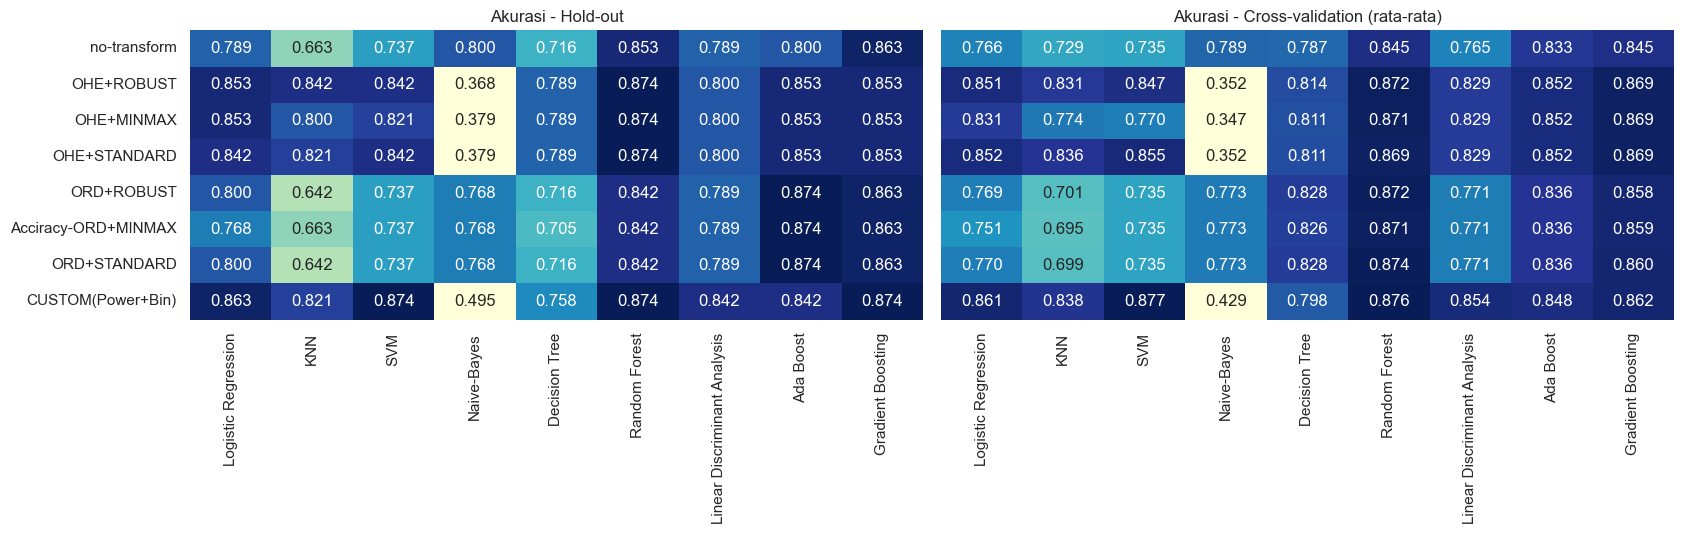

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True)
for a, (judul, tb) in zip(ax, [('Hold-out', tabel_ho), ('Cross-validation (rata-rata)', tabel_cv)]):
    m = tb.set_index('Model').T
    m.index = [i.replace('Accuracy-', '') for i in m.index]
    sns.heatmap(m, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0.55, ax=a, cbar=False)
    a.set_title(f'Akurasi - {judul}')
    a.set_xlabel('')
plt.tight_layout()
plt.show()

### Per model: rata-rata akurasi CV tanpa transformasi vs. varian terbaik

In [45]:
rows = []
for nama in cv_hasil['NO_TRANSFORM']:
    base = cv_hasil['NO_TRANSFORM'][nama]
    best_v = max(VARIAN, key=lambda v: cv_hasil[v][nama])
    rows.append({'Model': nama, 'CV no=transform': base, 'Varian terbaik': best_v, 'CV varian terbaik': cv_hasil[best_v][nama], 'Selisih': cv_hasil[best_v][nama] - base})
pd.DataFrame(rows).round(4)

,Model,CV no=transform,Varian terbaik,CV varian terbaik,Selisih
0,Logistic Regression,0.7662,CUSTOM,0.8609,0.0947
1,KNN,0.7294,CUSTOM,0.8376,0.1082
2,SVM,0.7352,CUSTOM,0.8772,0.1420
3,Naive-Bayes,0.7895,ORD_ROBUST,0.7733,-0.0163
4,Decision Tree,0.7868,ORD_ROBUST,0.8284,0.0416
5,Random Forest,0.8453,CUSTOM,0.8764,0.0311
6,Linear Discriminant Analysis,0.7655,CUSTOM,0.8538,0.0883
7,Ada Boost,0.8334,OHE_ROBUST,0.8517,0.0183
8,Gradient Boosting,0.8446,OHE_ROBUST,0.8694,0.0247


In [47]:
raw3 = bersihkan_dan_rekayasa_fitur(extract())
y3 = raw3['lulus_bin']
X3 = raw3.drop(columns=['lulus', 'lulus_bin'])

uji = ['Logistic Regression', 'SVM', 'Random Forest', 'Gradient Boosting']
rows = []
for v in ['OHE_STANDARD', 'CUSTOM']:
    for nama in uji:
        pipe = Pipeline([('ct', buat_column_transformer(v)), ('model', buat_model()[nama])])
        skor = cross_val_score(pipe, X3, y3, cv=CV, scoring='accuracy').mean()
        rows.append({'Varian': v, 'Model': nama, 'CV via file ETL (seluruh data)': cv_hasil[v][nama], 'CV via Pipeline (tanpa bocor)': skor})
cek = pd.DataFrame(rows)
cek['Selisih'] = cek['CV via Pipeline (tanpa bocor)'] - cek['CV via file ETL (seluruh data)']
cek.round(4)

,Varian,Model,CV via file ETL (seluruh data),CV via Pipeline (tanpa bocor),Selisih
0,OHE_STANDARD,Logistic Regression,0.8517,0.8524,0.0007
1,OHE_STANDARD,SVM,0.8545,0.8545,0.0000
2,OHE_STANDARD,Random Forest,0.8694,0.8659,-0.0035
3,OHE_STANDARD,Gradient Boosting,0.8687,0.8694,0.0007
4,CUSTOM,Logistic Regression,0.8609,0.8672,0.0064
5,CUSTOM,SVM,0.8772,0.8779,0.0007
6,CUSTOM,Random Forest,0.8764,0.8764,-0.0000
7,CUSTOM,Gradient Boosting,0.8616,0.8630,0.0014


## 5. Kesimpulan

In [52]:
nt = ring.loc[LABEL['NO_TRANSFORM']]
terbaik = ring['rata2 CV'].drop(LABEL['NO_TRANSFORM']).idxmax()
print(f"Majority baseline                        : {MAJORITY:.4f}")
print(f"Rata-rata akurasi CV tanpa transformasi  : {nt['rata2 CV']:.4f}")
print(f"Skenario transformasi terbaik (rata2 CV) : {terbaik} = {ring.loc[terbaik, 'rata2 CV']:.4f}")
print(f"Selisih                                  : {ring.loc[terbaik, 'rata2 CV'] - nt['rata2 CV']:+.4f}")
bm = max(((v, m, a) for v in VARIAN for m, a in cv_hasil[v].items()), key=lambda t: t[2])
print(f"Kombinasi model+transformasi terbaik (CV): {bm[1]} + {bm[0]} = {bm[2]:.4f}")
bn = max(cv_hasil['NO_TRANSFORM'].items(), key=lambda t: t[1])
print(f"Model terbaik tanpa transformasi (CV)    : {bn[0]} = {bn[1]:.4f}")

Majority baseline                        : 0.7352
Rata-rata akurasi CV tanpa transformasi  : 0.7884
Skenario transformasi terbaik (rata2 CV) : Accuracy-CUSTOM(Power+Bin) = 0.8047
Selisih                                  : +0.0163
Kombinasi model+transformasi terbaik (CV): SVM + CUSTOM = 0.8772
Model terbaik tanpa transformasi (CV)    : Random Forest = 0.8453


### Hasil

| Ukuran (rata-rata CV, 9 model) | Tanpa transformasi | Transformasi terbaik (`CUSTOM`) | Selisih |
|---|---|---|---|
| Semua model | 0,7885 | 0,8047 | +0,016 |
| Tanpa Naive-Bayes | 0,7884 | 0,8517 | +0,063 |
| Model terbaik | 0,8453 (RandomForest) | 0,8772 (SVM) | +0,032 |

Sebagai acuan, menebak "Ya" untuk semua pelamar sudah menghasilkan akurasi 0,7352.

### Interpretasi
1. Transformasi meningkatkan akurasi, terutama untuk model yang peka terhadap skala/jarak. SVM, KNN, Logistic Regression, dan LDA naik sekitar +9 sampai +14 poin (CV) setelah transformasi karena fitur kategorikal terpisah menjadi kolom One-Hot yang benar dan skor tes berada pada skala yang sebanding. Pada baseline, kode integer `LabelEncoder` untuk `kampus` (ratusan kode) atau `bidang` menciptakan jarak/urutan yang tidak bermakna.
2. Model berbasis pohon (Decision Tree, Random Forest, Boosting) hampir tidak membutuhkan scaling, sehingga kenaikannya kecil (sekitar +2 sampai +4 poin, dan pada beberapa hold-out justru turun sedikit). Mereka sudah cukup baik tanpa transformasi.
3. Naive-Bayes turun drastis pada varian One-Hot/`CUSTOM` (CV 0,35-0,43). Ini bukan kesalahan transformasi, melainkan asumsi `GaussianNB`, yaitu model ini mengira setiap fitur berdistribusi normal kontinu, sedangkan kolom One-Hot biner dan jarang (sparse) melanggar asumsi tersebut. Pada varian `ORD`, Naive-Bayes kembali ke ±0,77.
4. Pilihan encoder dan scaler berpengaruh. Untuk model berbasis jarak, One-Hot lebih baik daripada Ordinal Encoder (urutan alfabet pada `bidang`/`kampus` tidak bermakna). Pada One-Hot, `MinMaxScaler` terendah karena outlier menekan sebagian besar data ke rentang sempit. `RobustScaler` dan `StandardScaler` hampir sama. Varian `CUSTOM` (Yeo-Johnson untuk skor + 5 bin untuk `skor_total` + indikator `kampus_terisi`) menghasilkan rata-rata dan akurasi tertinggi.